# Train Punctuality & Run-Time Analysis: Milton Keynes Central to London Euston

I travel on this route, so I wanted to understand **why peak trains travelling to London are late most of the times** and whether the timetable itself is part of the problem.

**Questions:**
1. How punctual is the service (On Time, Time to 3, PPM)?
2. Where along the route do trains lose time?
3. Are any planned run times unrealistic (unachievable)?
4. Which services cause the most delay?
5. If we change the timetable, how much would punctuality improve? (Monte-Carlo simulation)

**Data:** simulated train movement data in the same format as Network Rail's train movement records (planned vs actual times at each station). It covers July–October 2026. I used a simulated dataset (see `data/generate_data.py`).

## 1. Load the data

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/train_movements.csv")
print(df.shape)
df.head()

(46451, 11)


,service_date,headcode,train_id,origin_dep_time,stop_seq,station_code,station_name,planned_arr,actual_arr,planned_dep,actual_dep
0,2026-08-10,2K05,2K050810,07:01,6,KGL,Kings Langley,2026-08-10 07:32:00,2026-08-10 07:32:08,2026-08-10 07:33:00,2026-08-10 07:33:11
1,2026-10-28,2K27,2K271028,16:16,3,TRI,Tring,2026-10-28 16:32:00,2026-10-28 16:32:55,2026-10-28 16:33:00,2026-10-28 16:33:49
2,2026-08-01,2K04,2K040801,06:46,4,BKM,Berkhamsted,2026-08-01 07:07:00,2026-08-01 07:07:18,2026-08-01 07:08:00,2026-08-01 07:08:00
3,2026-07-12,2K19,2K190712,12:16,4,BKM,Berkhamsted,2026-07-12 12:37:00,2026-07-12 12:36:52,2026-07-12 12:38:00,2026-07-12 12:38:00
4,2026-08-29,2K35,2K350829,20:16,9,WMB,Wembley Central,2026-08-29 21:05:00,2026-08-29 21:05:14,2026-08-29 21:06:00,2026-08-29 21:06:00


Each row is **one train at one station**. `stop_seq` is the station order (1 = Milton Keynes, 10 = Euston). `train_id` = headcode + date, so one journey on one day.

## 2. Clean the data

In [5]:
# remove duplicate rows (same record sent twice)
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()



Duplicates: 231


In [8]:
# convert time columns from text to datetime
time_cols = ["planned_arr", "actual_arr", "planned_dep", "actual_dep"]
for col in time_cols:
    df[col] = pd.to_datetime(df[col])


In [9]:

df["service_date"] = pd.to_datetime(df["service_date"])
print("Journeys:", df["train_id"].nunique())
df.isna().sum()

Journeys: 4622


service_date          0
headcode              0
train_id              0
origin_dep_time       0
stop_seq              0
station_code          0
station_name          0
planned_arr        4622
actual_arr         5140
planned_dep        4622
actual_dep         4622
dtype: int64

In [10]:
print("Extra missing values for 'actual_arr':",df["actual_arr"].isna().sum()-df["planned_arr"].isna().sum())

Extra missing values for 'actual_arr': 518


`planned_arr` is empty for 4,622 rows. That's true because the first station has no arrival, because the train starts there. `actual_arr` has 518 extra missing values: these are records that were never received. I kept them, and they're ignored when calculating lateness.

In [11]:
# lateness in minutes: departure lateness at the first station, arrival lateness everywhere else
arr_late = (df["actual_arr"] - df["planned_arr"]).dt.total_seconds() / 60
dep_late = (df["actual_dep"] - df["planned_dep"]).dt.total_seconds() / 60
df["late_min"] = np.where(df["stop_seq"] == 1, dep_late, arr_late)


In [12]:
# peak = weekday trains leaving MK between 06:30-09:30 or 16:00-18:30
dep = pd.to_datetime(df["origin_dep_time"], format="%H:%M")
mins = dep.dt.hour * 60 + dep.dt.minute
weekday = df["service_date"].dt.dayofweek < 5
df["peak"] = weekday & (mins.between(390, 570) | mins.between(960, 1110))

# example: one journey
df[df["train_id"] == "2K080915"].sort_values("stop_seq")[["station_name", "planned_arr", "actual_arr", "late_min"]]

,station_name,planned_arr,actual_arr,late_min
40081,Milton Keynes Central,NaT,NaT,1.533333
13674,Leighton Buzzard,2026-09-15 07:53:00,2026-09-15 07:54:31,1.516667
11662,Tring,2026-09-15 08:02:00,2026-09-15 08:04:19,2.316667
12371,Berkhamsted,2026-09-15 08:07:00,2026-09-15 08:09:34,2.566667
19696,Hemel Hempstead,2026-09-15 08:12:00,2026-09-15 08:14:24,2.400000
38161,Kings Langley,2026-09-15 08:17:00,2026-09-15 08:18:44,1.733333
19890,Watford Junction,2026-09-15 08:22:00,2026-09-15 08:23:48,1.800000
5919,Harrow & Wealdstone,2026-09-15 08:30:00,2026-09-15 08:32:57,2.950000
37644,Wembley Central,2026-09-15 08:35:00,2026-09-15 08:38:33,3.550000
13635,London Euston,2026-09-15 08:45:00,2026-09-15 08:49:37,4.616667


## 3. Punctuality at London Euston
- **On Time**: less than 1 minute late
- **Time to 3**: less than 3 minutes late
- **PPM**: less than 5 minutes late (the threshold for London & South East services)

In [13]:
euston = df[(df["station_code"] == "EUS") & df["late_min"].notna()]

def punctuality(late):
    return pd.Series({
        "trains": len(late),
        "On Time %": (late < 1).mean() * 100,
        "Time to 3 %": (late < 3).mean() * 100,
        "PPM %": (late < 5).mean() * 100,
        "avg minutes late": late.mean(),
    })

summary = pd.DataFrame({
    "All": punctuality(euston["late_min"]),
    "Off-peak": punctuality(euston[~euston["peak"]]["late_min"]),
    "Peak": punctuality(euston[euston["peak"]]["late_min"]),
}).round(1)
summary

,All,Off-peak,Peak
trains,4562.0,3174.0,1388.0
On Time %,62.9,84.5,13.5
Time to 3 %,86.7,96.5,64.3
PPM %,95.6,97.7,90.8
avg minutes late,1.3,0.6,2.9


In [14]:
# punctuality by month
euston.groupby(euston["service_date"].dt.month)["late_min"].apply(lambda x: (x < 1).mean() * 100).round(1)

service_date
7     63.6
8     65.3
9     62.2
10    60.6
Name: late_min, dtype: float64

**Finding:** off-peak trains are mostly on time, but **peak trains are On Time only about 13% of the time**. October is slightly worse than the other months, which fits with autumn leaf-fall.

## 4. Where do trains lose time?

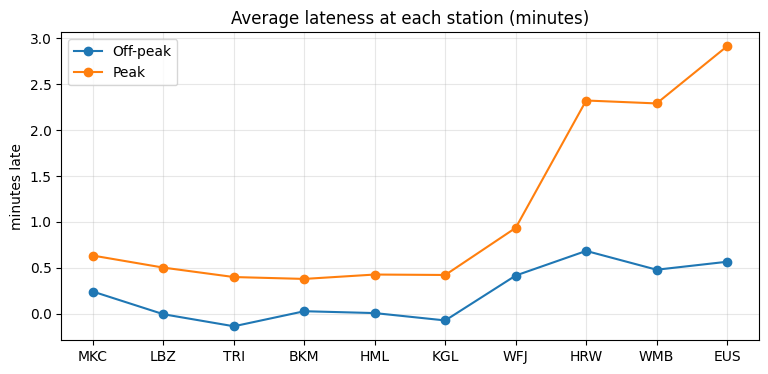

,,Off-peak,Peak
stop_seq,station_code,,
1,MKC,0.24,0.63
2,LBZ,-0.01,0.50
3,TRI,-0.14,0.40
4,BKM,0.03,0.38
5,HML,0.01,0.43
6,KGL,-0.07,0.42
7,WFJ,0.42,0.94
8,HRW,0.68,2.32
9,WMB,0.48,2.29


In [15]:
by_station = df.groupby(["stop_seq", "station_code", "peak"])["late_min"].mean().unstack()
by_station.columns = ["Off-peak", "Peak"]

stations = by_station.index.get_level_values("station_code")
plt.figure(figsize=(9, 4))
plt.plot(stations, by_station["Off-peak"], marker="o", label="Off-peak")
plt.plot(stations, by_station["Peak"], marker="o", label="Peak")
plt.title("Average lateness at each station (minutes)")
plt.ylabel("minutes late")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
by_station.round(2)

**Finding:** peak trains are fine until Kings Langley (KGL). Lateness then jumps between **Watford (WFJ) and Harrow (HRW)**, and again on the way into **Euston**.

## 5. Planned vs actual run times
Run time = time taken between two stations. For each section I check what % of trains completed it **within the planned time**. If it's under 50%, most trains can't keep to the timetable, so I mark the run time as **unachievable**.

In [17]:
runs = df.sort_values(["train_id", "stop_seq"]).copy()
prev = runs.groupby("train_id")
runs["section"] = prev["station_code"].shift() + " -> " + runs["station_code"]
runs["planned_run"] = (runs["planned_arr"] - prev["planned_dep"].shift()).dt.total_seconds() / 60
runs["actual_run"] = (runs["actual_arr"] - prev["actual_dep"].shift()).dt.total_seconds() / 60
runs = runs.dropna(subset=["section", "actual_run"])
runs["achieved"] = runs["actual_run"] <= runs["planned_run"]

peak_runs = runs[runs["peak"]]
sections = peak_runs.groupby(["stop_seq", "section"]).agg(
    planned=("planned_run", "median"),
    median_actual=("actual_run", "median"),
    p90_actual=("actual_run", lambda x: x.quantile(0.9)),
    achieved_pct=("achieved", lambda x: x.mean() * 100),
).round(1)
sections["unachievable"] = sections["achieved_pct"] < 50
sections

C:\Users\HP\AppData\Local\Temp\ipykernel_25660\2385212488.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  runs["achieved"] = runs["actual_run"] <= runs["planned_run"]


,,planned,median_actual,p90_actual,achieved_pct,unachievable
stop_seq,section,,,,,
2,MKC -> LBZ,7.0,6.8,7.6,63.0,False
3,LBZ -> TRI,8.0,7.7,8.6,65.0,False
4,TRI -> BKM,4.0,3.8,4.3,71.7,False
5,BKM -> HML,4.0,3.9,4.4,65.1,False
6,HML -> KGL,4.0,3.8,4.3,73.6,False
7,KGL -> WFJ,4.0,4.3,4.9,20.9,True
8,WFJ -> HRW,7.0,8.0,8.8,5.5,True
9,HRW -> WMB,4.0,3.8,4.4,68.1,False
10,WMB -> EUS,9.0,9.8,10.7,12.8,True


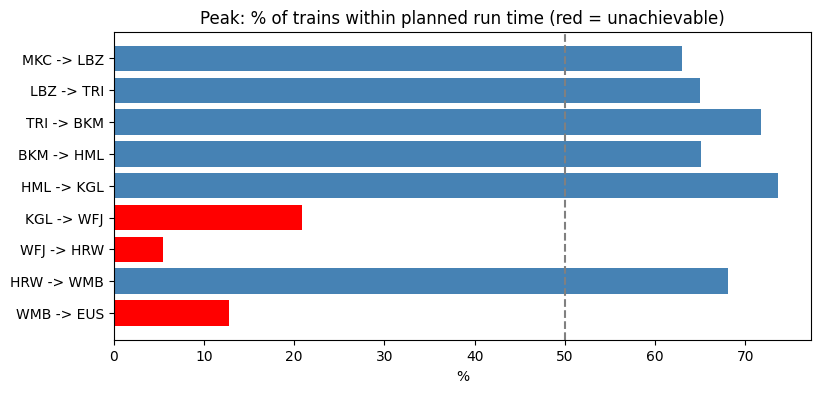

In [18]:
plt.figure(figsize=(9, 4))
colours = ["red" if x else "steelblue" for x in sections["unachievable"]]
plt.barh(sections.index.get_level_values("section"), sections["achieved_pct"], color=colours)
plt.axvline(50, color="grey", linestyle="--")
plt.gca().invert_yaxis()
plt.title("Peak: % of trains within planned run time (red = unachievable)")
plt.xlabel("%")
plt.show()

**Finding:** 3 peak sections are unachievable: **KGL → WFJ (21%)**, **WFJ → HRW (5%)** and **WMB → EUS (13%)**. Watford → Harrow is planned at 7 minutes, but the typical peak train takes 8.

## 6. Which services cause the most delay?

In [19]:
weekday_euston = euston[euston["service_date"].dt.dayofweek < 5]
start_delay = df[(df["stop_seq"] == 1) & (df["service_date"].dt.dayofweek < 5)].groupby("headcode")["late_min"].mean()

services = weekday_euston.groupby(["headcode", "origin_dep_time"]).agg(
    avg_late=("late_min", "mean"),
    delay_minutes=("late_min", lambda x: x.clip(lower=0).sum()),
).reset_index()
services["avg_start_delay"] = services["headcode"].map(start_delay)
services["share_of_delay_%"] = services["delay_minutes"] / services["delay_minutes"].sum() * 100
services = services.sort_values("delay_minutes", ascending=False).round(1)

print("Top 5 services = ", round(services.head(5)["share_of_delay_%"].sum(), 1), "% of all delay minutes")
services.head(10)

Top 5 services =  28.1 % of all delay minutes


,headcode,origin_dep_time,avg_late,delay_minutes,avg_start_delay,share_of_delay_%
7,2K08,07:46,4.2,364.6,3.0,6.7
27,2K28,16:46,3.6,309.8,0.4,5.7
11,2K12,08:46,3.4,299.1,2.2,5.5
28,2K29,17:16,3.2,281.4,0.3,5.2
8,2K09,08:01,3.2,272.9,0.2,5.0
9,2K10,08:16,2.9,258.8,1.6,4.8
26,2K27,16:16,2.9,252.1,0.3,4.7
4,2K05,07:01,2.9,252.0,0.2,4.7
12,2K13,09:16,2.7,236.5,0.3,4.4
10,2K11,08:31,2.8,235.1,0.2,4.3


**Finding:** 5 of 39 services cause about 28% of all weekday delay minutes, and they're all peak trains. The **07:46 (2K08)** is the worst, and it already leaves Milton Keynes about 3 minutes late. That's a late-start problem, not a run-time problem, so it needs a different fix.

## 7. Monte-Carlo simulation: testing a timetable change
I simulate 10,000 peak journeys. For each one, I randomly pick a real start delay, a real run time for every section and a real dwell time at every station, all taken from the data. Then I check whether the train arrives on time.

First I run it with the **current timetable** and compare it with the real data, to check the simulation is realistic. Then I test adding time to the unachievable sections.

In [20]:
# "bags" of real values from the peak data
run_bag = {s: g["actual_run"].values for s, g in peak_runs.groupby("section")}
start_bag = df[(df["stop_seq"] == 1) & df["peak"]]["late_min"].dropna().values

# dwell = time stood at a station (only trains that arrived late, because early trains wait for their departure time)
stops = df[df["peak"] & (df["stop_seq"] > 1) & (df["station_code"] != "EUS") & (df["late_min"] > 0)]
dwell = (stops["actual_dep"] - stops["actual_arr"]).dt.total_seconds() / 60
dwell_bag = {s: g.values for s, g in dwell.groupby(stops["station_code"])}

route = peak_runs.groupby(["stop_seq", "section", "station_code"])["planned_run"].median().reset_index()
route

,stop_seq,section,station_code,planned_run
0,2,MKC -> LBZ,LBZ,7.0
1,3,LBZ -> TRI,TRI,8.0
2,4,TRI -> BKM,BKM,4.0
3,5,BKM -> HML,HML,4.0
4,6,HML -> KGL,KGL,4.0
5,7,KGL -> WFJ,WFJ,4.0
6,8,WFJ -> HRW,HRW,7.0
7,9,HRW -> WMB,WMB,4.0
8,10,WMB -> EUS,EUS,9.0


In [21]:
def simulate(extra_time, n=10000, seed=1):
    rng = np.random.default_rng(seed)
    planned = np.zeros(n)
    actual = rng.choice(start_bag, n)          # start delay
    for _, row in route.iterrows():
        planned = planned + row["planned_run"] + extra_time.get(row["section"], 0)
        actual = actual + rng.choice(run_bag[row["section"]], n)
        if row["station_code"] == "EUS":
            break
        planned = planned + 1                  # 1 minute planned stop
        actual = np.maximum(actual + rng.choice(dwell_bag[row["station_code"]], n), planned)  # can't leave early
    return actual - planned                    # minutes late at Euston

real = euston[euston["peak"]]["late_min"]
sim = simulate({})
print("Real peak On Time:      ", round((real < 1).mean() * 100, 1), "%")
print("Simulated peak On Time: ", round((sim < 1).mean() * 100, 1), "%")

Real peak On Time:       13.5 %
Simulated peak On Time:  13.0 %


The simulation is within about 1 percentage point of the real data, so it's realistic enough to test changes.

In [22]:
scenarios = {
    "Current timetable": {},
    "+1 min WMB -> EUS": {"WMB -> EUS": 1},
    "+1 min WFJ -> HRW and WMB -> EUS": {"WFJ -> HRW": 1, "WMB -> EUS": 1},
}
results = {}
for name, extra in scenarios.items():
    late = simulate(extra)
    results[name] = late
    print(f"{name:35} On Time {(late < 1).mean()*100:5.1f}%   PPM {(late < 5).mean()*100:5.1f}%")

Current timetable                   On Time  13.0%   PPM  90.2%
+1 min WMB -> EUS                   On Time  36.8%   PPM  93.5%
+1 min WFJ -> HRW and WMB -> EUS    On Time  62.6%   PPM  95.2%


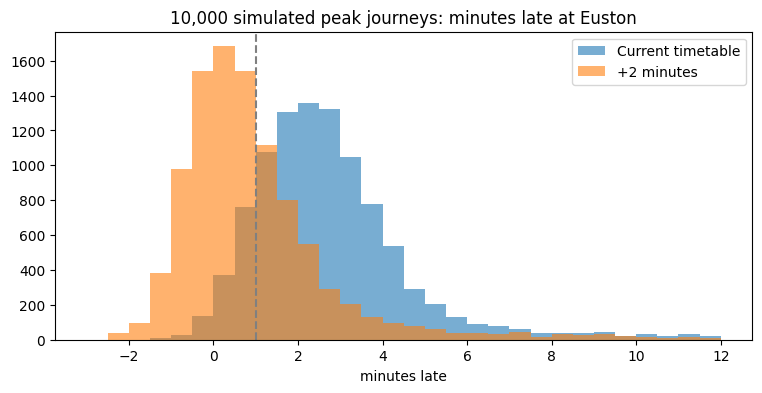

In [23]:
plt.figure(figsize=(9, 4))
bins = np.arange(-3, 12.5, 0.5)
plt.hist(results["Current timetable"], bins=bins, alpha=0.6, label="Current timetable")
plt.hist(results["+1 min WFJ -> HRW and WMB -> EUS"], bins=bins, alpha=0.6, label="+2 minutes")
plt.axvline(1, color="grey", linestyle="--")
plt.title("10,000 simulated peak journeys: minutes late at Euston")
plt.xlabel("minutes late")
plt.legend()
plt.show()

## 8. Conclusions
- Peak punctuality is the main problem: **13% On Time in the peak vs 85% off-peak**.
- The timetable is part of the cause: **3 peak run times are unachievable**, mainly Watford → Harrow and Wembley → Euston.
- Adding **2 minutes** to two sections raises simulated peak On Time from **about 13% to about 62%**. The trade-off is a longer advertised journey, which is a decision for timetable planners.
- The **07:46** has a separate late-start problem at Milton Keynes that should be looked at.

**Limitations:** the data is simulated. On Time is measured only at Euston. The simulation treats each train separately, without knock-on delay between trains.

**Next steps:** run the same analysis on real Network Rail data, and add knock-on delay to the simulation.